In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import numpy as np
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from textblob import TextBlob
from wordcloud import WordCloud

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

True

Q1

In [2]:
# Q1: Paragraph on the development of tones in languages (5 sentences)
paragraph = (
    "In tonal languages, pitch changes on a syllable can alter a word's actual meaning "
    "rather than just showing emotion or emphasis. Over generations, when speakers drop or "
    "soften certain sounds at the start or end of a syllable, the pitch on the nearby vowel "
    "often bends to make up for it. You can see this clearly across many East and Southeast "
    "Asian languages, where vanished consonant endings left behind rising, falling, or flat pitch "
    "contours. Eventually, those pitch shifts stop being a casual vocal quirk and become essential "
    "to telling words apart. A tiny change in how a sound is spoken can quietly reshape how a "
    "whole language works."
)

#a)
cleaned_text = re.sub(r"[^\w\s]", "", paragraph.lower())
print("1. Cleaned text:\n", cleaned_text, "\n")

# b)
sentences = sent_tokenize(paragraph)
words_nltk = word_tokenize(cleaned_text)
print("2. Sentences:", len(sentences))
for idx, s in enumerate(sentences, 1):
    print(f"   S{idx}: {s}")
print("\n   Word tokens (NLTK):", words_nltk, "\n")

# c)
words_split = cleaned_text.split()
print("3. split() count:", len(words_split), "| word_tokenize() count:", len(words_nltk))
print("   Difference (word_tokenize - split):", set(words_nltk) - set(words_split))
print("   Difference (split - word_tokenize):", set(words_split) - set(words_nltk), "\n")

# d)
stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words_nltk if w not in stop_words]
print("4. Filtered words (no stopwords):\n", filtered_words, "\n")

# e)
freq_dist = Counter(filtered_words)
print("5. Word frequency distribution (excluding stopwords):")
for word, count in freq_dist.most_common():
    print(f"   {word:<15}: {count}")

1. Cleaned text:
 in tonal languages pitch changes on a syllable can alter a words actual meaning rather than just showing emotion or emphasis over generations when speakers drop or soften certain sounds at the start or end of a syllable the pitch on the nearby vowel often bends to make up for it you can see this clearly across many east and southeast asian languages where vanished consonant endings left behind rising falling or flat pitch contours eventually those pitch shifts stop being a casual vocal quirk and become essential to telling words apart a tiny change in how a sound is spoken can quietly reshape how a whole language works 

2. Sentences: 5
   S1: In tonal languages, pitch changes on a syllable can alter a word's actual meaning rather than just showing emotion or emphasis.
   S2: Over generations, when speakers drop or soften certain sounds at the start or end of a syllable, the pitch on the nearby vowel often bends to make up for it.
   S3: You can see this clearly acros

Q2

In [3]:

# a)
alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
print("1. Alphabetic words:", alpha_words, "\n")

# b)
alpha_no_stops = [w for w in alpha_words if w not in stop_words]
print("2. Without stopwords:", alpha_no_stops, "\n")

# c)
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in alpha_no_stops]

# d)
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in alpha_no_stops]

# e)
print("3 & 4. Original -> Stemmed vs. Lemmatized:")
for orig, st, le in zip(alpha_no_stops, stemmed_words, lemmatized_words):
    if st != le or st != orig:
        print(f"   {orig:<15} -> stem: {st:<14} | lemma: {le}")

1. Alphabetic words: ['in', 'tonal', 'languages', 'pitch', 'changes', 'on', 'a', 'syllable', 'can', 'alter', 'a', 'word', 's', 'actual', 'meaning', 'rather', 'than', 'just', 'showing', 'emotion', 'or', 'emphasis', 'over', 'generations', 'when', 'speakers', 'drop', 'or', 'soften', 'certain', 'sounds', 'at', 'the', 'start', 'or', 'end', 'of', 'a', 'syllable', 'the', 'pitch', 'on', 'the', 'nearby', 'vowel', 'often', 'bends', 'to', 'make', 'up', 'for', 'it', 'you', 'can', 'see', 'this', 'clearly', 'across', 'many', 'east', 'and', 'southeast', 'asian', 'languages', 'where', 'vanished', 'consonant', 'endings', 'left', 'behind', 'rising', 'falling', 'or', 'flat', 'pitch', 'contours', 'eventually', 'those', 'pitch', 'shifts', 'stop', 'being', 'a', 'casual', 'vocal', 'quirk', 'and', 'become', 'essential', 'to', 'telling', 'words', 'apart', 'a', 'tiny', 'change', 'in', 'how', 'a', 'sound', 'is', 'spoken', 'can', 'quietly', 'reshape', 'how', 'a', 'whole', 'language', 'works'] 

2. Without stopwor

Stemming (PorterStemmer) chops off word suffixes heuristically without checking a dictionary or part of speech. That can produce truncated or non-dictionary roots (for example, turning "changes" into "chang", "languages" into "languag", or "consonant" into "conson"). Lemmatization (WordNetLemmatizer) uses lexical lookup (WordNet) to map inflected forms to a valid base word or lemma (such as "changes" $\rightarrow$ "change", "languages" $\rightarrow$ "language", "words" $\rightarrow$ "word"). Note that without passing a part-of-speech (POS) tag, WordNetLemmatizer defaults to noun (pos='n'), so verbs like "vanished" or "telling" may stay unlemmatized unless given a POS tag (e.g., pos='v').

When to prefer each: Prefer stemming when speed matters, vocabulary size needs aggressive reduction, and rough root matching is enough (e.g., quick search indexing or baseline keyword retrieval).Prefer lemmatization when interpretability, clean vocabulary/keywords, or grammatical accuracy matters (e.g., topic modeling, keyword extraction, or downstream NLP features).

Q3

In [4]:
 texts_q3 = [
    "Final stop consonants in syllable codas often trigger rising or falling pitch contours.",
    "Tone sandhi alters adjacent syllable pitches during connected speech in tonal languages.",
    "Pitch contour tracking helps speech recognition systems distinguish minimal tone pairs."
]

# a)
count_vec = CountVectorizer(stop_words="english")
bow_matrix = count_vec.fit_transform(texts_q3)
print("1. Bag of Words Vocabulary:", count_vec.get_feature_names_out())
print("   BoW Matrix:\n", bow_matrix.toarray(), "\n")

# b)
tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf_vec.fit_transform(texts_q3)
feature_names = np.array(tfidf_vec.get_feature_names_out())

# c)
print("3. Top 3 TF-IDF Keywords per Text:")
for idx, text in enumerate(texts_q3):
    row = tfidf_matrix[idx].toarray().flatten()
    top_indices = row.argsort()[::-1][:3]
    top_keywords = [(feature_names[i], round(float(row[i]), 4)) for i in top_indices]
    print(f"\n   Text {idx + 1}: \"{text}\"")
    print(f"   Top 3 keywords: {top_keywords}")

1. Bag of Words Vocabulary: ['adjacent' 'alters' 'codas' 'connected' 'consonants' 'contour' 'contours'
 'distinguish' 'falling' 'final' 'helps' 'languages' 'minimal' 'pairs'
 'pitch' 'pitches' 'recognition' 'rising' 'sandhi' 'speech' 'stop'
 'syllable' 'systems' 'tonal' 'tone' 'tracking' 'trigger']
   BoW Matrix:
 [[0 0 1 0 1 0 1 0 1 1 0 0 0 0 1 0 0 1 0 0 1 1 0 0 0 0 1]
 [1 1 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 1 1 0 1 0 1 1 0 0]
 [0 0 0 0 0 1 0 1 0 0 1 0 1 1 1 0 1 0 0 1 0 0 1 0 1 1 0]] 

3. Top 3 TF-IDF Keywords per Text:

   Text 1: "Final stop consonants in syllable codas often trigger rising or falling pitch contours."
   Top 3 keywords: [('trigger', 0.3305), ('rising', 0.3305), ('stop', 0.3305)]

   Text 2: "Tone sandhi alters adjacent syllable pitches during connected speech in tonal languages."
   Top 3 keywords: [('tonal', 0.3383), ('sandhi', 0.3383), ('pitches', 0.3383)]

   Text 3: "Pitch contour tracking helps speech recognition systems distinguish minimal tone pairs."
   Top 3 

Words that appear in only one of the three short texts (such as codas, sandhi, or recognition) get higher TF-IDF weights because they distinguish that document from the rest.

Terms shared across multiple texts (like pitch or syllable) receive lower relative IDF weight even when frequent, which helps surface more specific topical terms.

Q4

In [5]:
tech_a = """Automatic speech recognition converts spoken audio into readable text.
Acoustic models map sound waves to phonemes or subword units.
Language models score word sequences based on context and grammar.
Modern neural architectures improve accuracy across noisy speech.
They power voice assistants, dictation tools, and transcription systems."""

tech_b = """Blockchain is a distributed ledger replicated across network nodes.
Transactions are grouped into blocks linked cryptographically by hashes.
Consensus mechanisms help participants agree on valid ledger states.
Smart contracts execute predefined logic automatically on the network.
Immutability and transparency make it useful for auditable records."""


def preprocess_for_similarity(text):
    cleaned = re.sub(r"[^a-z\s]", " ", text.lower())
    tokens = word_tokenize(cleaned)
    stops = set(stopwords.words("english"))
    return [t for t in tokens if t not in stops and len(t) > 1]


tokens_a = preprocess_for_similarity(tech_a)
tokens_b = preprocess_for_similarity(tech_b)
print("1. Tokens A:", tokens_a)
print("   Tokens B:", tokens_b, "\n")

# Jaccard Similarity using sets
set_a, set_b = set(tokens_a), set(tokens_b)
jaccard_sim = len(set_a & set_b) / len(set_a | set_b)
print("2a. Shared tokens (intersection):", set_a & set_b)
print(f"    Jaccard Similarity: {jaccard_sim:.4f}\n")

# Cosine Similarity
tfidf_q4 = TfidfVectorizer()
tfidf_mat_q4 = tfidf_q4.fit_transform([" ".join(tokens_a), " ".join(tokens_b)])
cos_sim = cosine_similarity(tfidf_mat_q4[0:1], tfidf_mat_q4[1:2])[0][0]
print(f"2b. Cosine Similarity: {cos_sim:.4f}")

1. Tokens A: ['automatic', 'speech', 'recognition', 'converts', 'spoken', 'audio', 'readable', 'text', 'acoustic', 'models', 'map', 'sound', 'waves', 'phonemes', 'subword', 'units', 'language', 'models', 'score', 'word', 'sequences', 'based', 'context', 'grammar', 'modern', 'neural', 'architectures', 'improve', 'accuracy', 'across', 'noisy', 'speech', 'power', 'voice', 'assistants', 'dictation', 'tools', 'transcription', 'systems']
   Tokens B: ['blockchain', 'distributed', 'ledger', 'replicated', 'across', 'network', 'nodes', 'transactions', 'grouped', 'blocks', 'linked', 'cryptographically', 'hashes', 'consensus', 'mechanisms', 'help', 'participants', 'agree', 'valid', 'ledger', 'states', 'smart', 'contracts', 'execute', 'predefined', 'logic', 'automatically', 'network', 'immutability', 'transparency', 'make', 'useful', 'auditable', 'records'] 

2a. Shared tokens (intersection): {'across'}
    Jaccard Similarity: 0.0147

2b. Cosine Similarity: 0.0127


Because Automatic Speech Recognition and Blockchain belong to distinct domains, both Jaccard and Cosine similarity scores will be low—which matches the expectation that two unrelated technologies share little vocabulary.

Cosine similarity on TF-IDF vectors generally gives better analytical insight than raw set-based Jaccard similarity because it accounts for term weighting (importance) and vector angle/magnitude rather than treating every unique word as an unweighted binary presence/absence flag. Jaccard similarity is straightforward and intuitive for measuring pure vocabulary overlap, but it ignores how often a word appears or how distinctive it is.

Q5

1 & 2. Polarity, Subjectivity, and Sentiment Classification:

   Review 1 [Positive] (polarity=+0.57, subjectivity=0.71)
     "The tone practice exercises are super helpful and the audio clarity is great."
   Review 2 [Negative] (polarity=-0.26, subjectivity=0.75)
     "The app crashes every time I open the pronunciation lessons. Very frustrating."
   Review 3 [Positive] (polarity=+0.18, subjectivity=0.39)
     "It has a clean layout and basic word lists, nothing particularly standout."
   Review 4 [Positive] (polarity=+0.35, subjectivity=0.40)
     "Love the slow-down playback feature—it makes hearing pitch changes much easier."
   Review 5 [Neutral] (polarity=+0.00, subjectivity=0.00)
     "Customer support never replied to my billing question and the export feature is buggy."
   Review 6 [Positive] (polarity=+0.30, subjectivity=0.50)
     "The daily streak reminders are nice and the practice drills feel well organized."


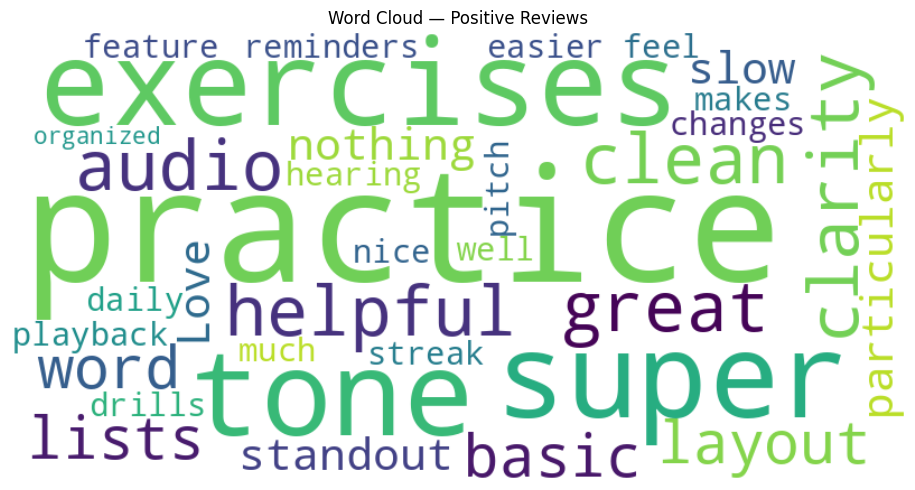

In [6]:
reviews = [
    "The tone practice exercises are super helpful and the audio clarity is great.",
    "The app crashes every time I open the pronunciation lessons. Very frustrating.",
    "It has a clean layout and basic word lists, nothing particularly standout.",
    "Love the slow-down playback feature—it makes hearing pitch changes much easier.",
    "Customer support never replied to my billing question and the export feature is buggy.",
    "The daily streak reminders are nice and the practice drills feel well organized."
]

positive_reviews = []
print("1 & 2. Polarity, Subjectivity, and Sentiment Classification:\n")

for idx, rev in enumerate(reviews, 1):
    blob = TextBlob(rev)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity

    if polarity > 0.05:
        label = "Positive"
        positive_reviews.append(rev)
    elif polarity < -0.05:
        label = "Negative"
    else:
        label = "Neutral"

    print(f"   Review {idx} [{label}] (polarity={polarity:+.2f}, subjectivity={subjectivity:.2f})")
    print(f"     \"{rev}\"")

pos_corpus = " ".join(positive_reviews)
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color="white",
    stopwords=stop_words,
    collocations=False
).generate(pos_corpus)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud — Positive Reviews")
plt.tight_layout()
plt.show()

In [7]:
corpus_q6 = """
Languages often develop lexical tones gradually through sound changes in adjacent consonants.
When speakers weaken or drop syllable final consonants over centuries, pitch contours on the
preceding vowel frequently shift to preserve distinctions between words. Historical linguists
call this process tonogenesis, and it has occurred independently across multiple language
families around the world. In many tonal languages, rising, falling, high, or low pitch patterns
carry grammatical or lexical information just like consonants and vowels. Over time, subtle
phonetic pitch differences become phonemic categories that native speakers use effortlessly
every day. Studying how tones emerge and shift reveals how sound systems adapt while keeping
communication clear.
""".strip()

print("Training word count:", len(corpus_q6.split()))

import tensorflow as tf
from tensorflow.keras.layers import Dense, Embedding, LSTM
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer()
tokenizer.fit_on_texts([corpus_q6])
total_words = len(tokenizer.word_index) + 1

input_sequences = []
for line in corpus_q6.splitlines():
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        input_sequences.append(token_list[: i + 1])

max_seq_len = max(len(seq) for seq in input_sequences)
padded_sequences = np.array(
    pad_sequences(input_sequences, maxlen=max_seq_len, padding="pre")
)

X = padded_sequences[:, :-1]
y = tf.keras.utils.to_categorical(padded_sequences[:, -1], num_classes=total_words)

model = Sequential([
    Embedding(input_dim=total_words, output_dim=32, input_length=max_seq_len - 1),
    LSTM(64),
    Dense(total_words, activation="softmax")
])

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

model.fit(X, y, epochs=150, verbose=0)

index_to_word = {v: k for k, v in tokenizer.word_index.items()}


def generate_text(seed_text, num_words_to_generate=24):
    result = seed_text
    for _ in range(num_words_to_generate):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=max_seq_len - 1, padding="pre")
        pred_idx = int(np.argmax(model.predict(seq, verbose=0), axis=-1)[0])
        next_word = index_to_word.get(pred_idx, "")
        if not next_word:
            break
        result += " " + next_word
    return result


seed_word = "tones"
generated = generate_text(seed_word, num_words_to_generate=24)

words_out = generated.split()
lines_out = [" ".join(words_out[i : i + 9]) for i in range(0, len(words_out), 9)]
print("\nGenerated text (seed =", repr(seed_word) + "):\n")
for line in lines_out[:3]:
    print(" ", line)

Training word count: 105


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(



Generated text (seed = 'tones'):

  tones often lexical lexical tones gradually sound sound changes
  in adjacent consonants while keeping keeping keeping keeping keeping
  keeping keeping keeping keeping on on the
